In [1]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config

# Bright

In [59]:
L = 80
N = 10_001
Nt = 10_000 #10_000
tf = 15

k = 1/4

pars = {"k":k}
c = np.sqrt(2)/2
w = 1 #np.sqrt(2)/2

w_bright_theo, x_bright = soliton(c, k, w=w, soliton_type="bright", L=L, N=N, as_func=True)

Creating soliton...
Soliton created


In [63]:
def bright_soliton(x, t, c=c, w=w, x_0=0):
    i = 1j
    output = w_moving_theo(x-c*t-x_0) * np.exp(i*(-c**2/4*t-w*t))
    return output

In [64]:
w_bright = Foc.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_bright.set_w_theo(bright_soliton)
w_bright.solve()

Iteration  1  of  10000 . Error:  1.1303005521868292e-11 . Newton iterations:  3
Iteration  2  of  10000 . Error:  1.1303478656057817e-11 . Newton iterations:  3
Iteration  3  of  10000 . Error:  1.1304899814086767e-11 . Newton iterations:  3
Iteration  4  of  10000 . Error:  1.130730327669117e-11 . Newton iterations:  3
Iteration  5  of  10000 . Error:  1.131065437622026e-11 . Newton iterations:  3
Iteration  6  of  10000 . Error:  1.1314947188596944e-11 . Newton iterations:  3
Iteration  7  of  10000 . Error:  1.1320188062012228e-11 . Newton iterations:  3
Iteration  8  of  10000 . Error:  1.132640363644008e-11 . Newton iterations:  3
Iteration  9  of  10000 . Error:  1.13335145159819e-11 . Newton iterations:  3
Iteration  10  of  10000 . Error:  1.1341624819627399e-11 . Newton iterations:  3
Iteration  11  of  10000 . Error:  1.1350686412386137e-11 . Newton iterations:  3
Iteration  12  of  10000 . Error:  1.1360668533599984e-11 . Newton iterations:  3
Iteration  13  of  10000 . Err

In [81]:
def sol_gauss(x, A):
    output = w_bright_theo(x) - A*np.exp(-x**2)
    return output

A = 0.02041595129863531 #7e-2#roots[1]-0.02
init_cond = lambda x: sol_gauss(x, A)

w_bright_gauss_007 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_bright_gauss_007.set_init_condition(init_cond)
w_bright_gauss_007.solve()

Iteration  1  of  10000 . Newton Error:  5.2434761866370225e-15 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  5.228162659189722e-15 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  5.454100673749212e-15 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  4.912146402003662e-15 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  5.015348461953181e-15 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  5.174698312127791e-15 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  5.293541927510981e-15 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  5.662645403298289e-15 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  5.0919458400919995e-15 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  5.701619892681474e-15 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  5.2724964284713156e-15 . Total iteration:  2
Iteration  12  of  10000 . Newton Error:  6.192921562655339e

In [86]:
w_bright.w_theo = bright_soliton
w_bright_gauss_007.w_theo = bright_soliton

L2_errors_bright = w_bright.get_error()
L2_errors_bright_gauss_007 = w_bright_gauss_007.get_error()

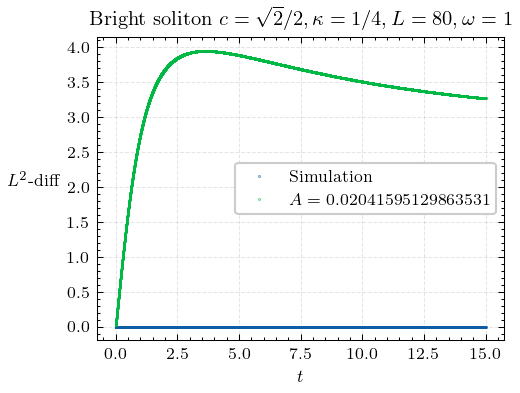

In [122]:
ms = .5
plt.plot(w_bright.t, L2_errors_bright, ".", label="Simulation", ms=ms)
plt.plot(w_bright.t, L2_errors_bright_gauss_007, ".", label=r"$A={}$".format(A), ms=ms)

plt.xlabel(r"$t$")
plt.ylabel(r"$L^2$-diff", rotation='horizontal', ha='right')
#plt.yscale("log")
plt.legend()
plt.title(r"Bright soliton $c=\sqrt{2}/2, \kappa=1/4, L=80, \omega=1$")
plt.savefig("diffs/bright.png", dpi=300, bbox_inches = "tight")
plt.show()

# Dark in $D_1$

In [40]:
k = 1/4
pars = {"k":k}
c = np.sqrt(2)/2

In [35]:
L = 80
N = 10_001
Nt = 10_000 #10_000
tf = 15

w_dark_st_D1, x_dark_st_D1 = soliton(c, k, soliton_type="dark", L=L, N=N, as_func=True)

w_st_D1 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_st_D1.set_init_condition(w_dark_st_D1)
w_st_D1.solve()

Creating soliton...
Soliton created
Iteration  1  of  10000 . Newton Error:  1.7839030548048398e-14 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  2.2259844747549728e-14 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  2.4524635042788646e-14 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  2.3863454448661136e-14 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  2.537070604527634e-14 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  2.6381054810814854e-14 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  2.7138817585604888e-14 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  2.5448791372653803e-14 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  2.655741838142834e-14 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  2.7003254264904556e-14 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  2.8241694038501877e-14 . Total iteration:  2
Iteration  12  of 

In [80]:
import scipy.integrate as integrate

i = 1j
def g(x, A):
    return A * np.exp(-x**2)

def g_1(x, A):
    return -2 * A * x * np.exp(-x**2)

def g_2(x, A):
    return -2 * A * np.exp(-x**2) + 4 * A * x**2 * np.exp(-x**2)

def inner(x, y):
    return np.real(np.conjugate(x) * y)

def integrand(x, A, k, c=c):
    h = x[1] - x[0]
    u = w_dark_st_D1(x)
    u_1 = np.gradient(u, h)
    u_2 = np.gradient(u_prime, h)
    
    g_ = g(x, A)
    g_1_ = g_1(x, A)
    g_2_ = g_2(x, A)

    output_1 = inner(u, i*(g_*(1-norm(u + g_)) +g_2_) - c*g_1_)
    output_2 = k * inner(u_2*g_+2*u_1*g_1_+u*g_2_, i*(norm(u) + g_**2 + 2*inner(u,g_)))
    return output_1 - output_2

def m_t_0(x, A, k):
    J = x.size
    #h = x[1] - x[0]
    #integrand_ = integrand(x, A, k)

    output = integrate.trapezoid(integrand(x, A, k), x)
    #integ = h/2 * (integrand_[0] + integrand_[1])
    
    #for j in range(J-1):
    #    integ = integ + (h/2 * (integrand_[j] + integrand_[j+1]))

    return 2*output#integ

In [81]:
slope = m_t_0(x_dark_st_D1, A, k)
m_0 = A * (np.pi/2)**(1/4)
slope

-1.3877787807814457e-17

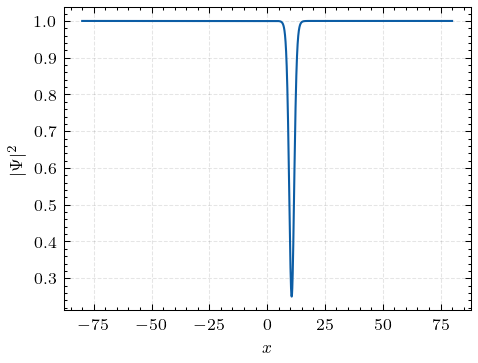

In [100]:
w_st_D1.plot(w_st_D1.t[-1])

In [37]:
def theo_dark_st_D1(x, t):
    output = w_dark_st_D1(x - c*t)
    return output

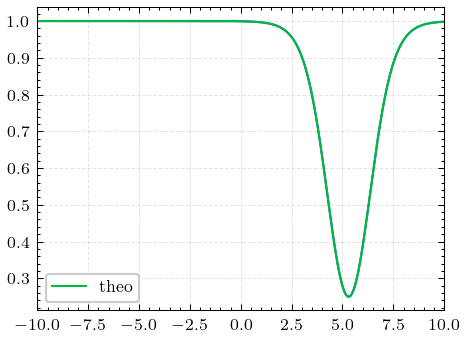

In [92]:
j = 5000
plt.plot(w_st_D1.x, norm(w_st_D1.w[j]), marker="none", ls="-")
plt.plot(w_st_D1.x, norm(theo_dark_st_D1(w_st_D1.x, w_st_D1.t[j])), marker="none", ls="-", label="theo")
plt.legend()
plt.xlim(-10, 10)

plt.show()

In [38]:
def sol_gauss(x, A):
    output = w_dark_st_D1(x) + A*np.exp(-x**2)
    return output

A = 2e-2 #0.02041595129863531 #7e-2#roots[1]-0.02
init_cond = lambda x: sol_gauss(x, A)

w_st_D1_gauss_007 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_st_D1_gauss_007.set_init_condition(init_cond)
w_st_D1_gauss_007.solve()#method="fixed point")

Iteration  1  of  10000 . Newton Error:  1.7776443136019103e-14 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  2.2381597729602278e-14 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  2.4421726960366842e-14 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  2.3872529277051007e-14 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  2.534434954337755e-14 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  2.6351454531144755e-14 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  2.7166036850382002e-14 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  2.5371607617298597e-14 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  2.6628831201332754e-14 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  2.6930507395111614e-14 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  2.818644857537474e-14 . Total iteration:  2
Iteration  12  of  10000 . Newton Error:  2.6042483566

In [47]:
w_st_D1.w_theo = theo_dark_st_D1
w_st_D1_gauss_007.w_theo = theo_dark_st_D1
#w_in_gauss_001.w_theo = theo_dark_in
#w_in_gauss_0001.w_theo = theo_dark_in
#w_in_gauss_00001.w_theo = theo_dark_in

L2_errors_st_D1 = w_st_D1.get_error()#np.zeros(len(w_in.w)-1)
L2_errors_st_D1_gauss_007 = w_st_D1_gauss_007.get_error()#np.zeros(len(w_in.w)-1)
#errors_gauss_001 = w_in_gauss_001.get_error()#np.zeros(len(w_in.w)-1)
#errors_gauss_0001 = w_in_gauss_0001.get_error()#np.zeros(len(w_in.w)-1)
#errors_gauss_00001 = w_in_gauss_00001.get_error()#np.zeros(len(w_in.w)-1)


In [51]:
slope

1.4698562064000892e-17

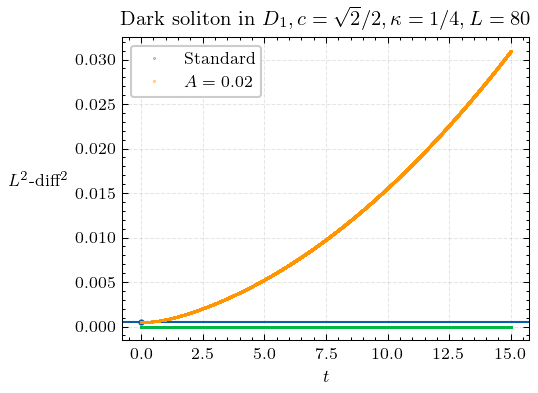

In [50]:
slope = m_t_0(x_dark_st_D1, A, k)
m_0 = A * (np.pi/2)**(1/4)

ms = .5

plt.plot(0, m_0**2, ms=2)
plt.axline((0, m_0**2), slope=slope, linewidth=1)
plt.plot(w_st_D1.t, L2_errors_st_D1**2, ".", label="Standard", ms=ms)
plt.plot(w_st_D1.t, L2_errors_st_D1_gauss_007**2, ".", label=r"$A={}$".format(A), ms=ms)
#plt.plot(w_in.t, errors_gauss_001, ".", label=r"Gauss $A=10^{-2}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_0001, ".", label=r"Gauss $A=10^{-3}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_00001, ".", label=r"Gauss $A=10^{-4}$", ms=ms)
plt.xlabel(r"$t$")
plt.ylabel(r"$L^2$-diff$^2$", rotation='horizontal', ha='right')
plt.title(r"Dark soliton in $D_1, c=\sqrt{2}/2, \kappa=1/4, L=80$")
#plt.yscale("log")
plt.legend()
plt.savefig("diffs/Dark_D1.png", dpi=300, bbox_inches = "tight")
plt.show()

# Dark in $D_2$

In [2]:
k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)
print("c* = ", c_star)

eps = 0.1
c_st = c_star + eps

c* =  0.4734813690779277


In [3]:
c_st

0.5734813690779277

In [4]:
L = 400 #80
N = 10_001
Nt = 10_000 #10_000
tf = 2#1 #15

w_dark_st, x_dark_st = soliton(c_st, k, soliton_type="dark", L=L, N=N, as_func=True)

Creating soliton...
Soliton created


In [81]:
i = 1j
def g(x, A):
    return A * np.exp(-x**2)

def g_1(x, A):
    return -2 * A * x * np.exp(-x**2)

def g_2(x, A):
    return -2 * A * np.exp(-x**2) + 4 * A * x**2 * np.exp(-x**2)

def inner(x, y):
    return np.real(np.conjugate(x) * y)

def integrand(x, A, k, c=c_st):
    h = x[1] - x[0]
    u = w_dark_st(x)
    u_1 = np.gradient(u, h)
    u_2 = np.gradient(u_prime, h)
    
    g_ = g(x, A)
    g_1_ = g_1(x, A)
    g_2_ = g_2(x, A)

    output_1 = inner(u, i*(g_*(1-norm(u + g_)) -g_2_) - c*g_1_)
    output_2 = k * inner(u_2*g_+2*u_1*g_1_+u*g_2_, i*(norm(u) + g_**2 + u*g_))
    return output_1 + output_2

def m_t_0(x, A, k):
    J = x.size
    h = x[1] - x[0]
    integrand_ = integrand(x, A, k)
    integ = h/2 * (integrand_[0] + integrand_[1])
    
    for j in range(J-1):
        integ = integ + (h/2 * (integrand_[j] + integrand_[j+1]))

    return 2*integ

In [82]:
w_st = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_st.set_init_condition(w_dark_st)
w_st.solve(b_tol=1e-4)#method="fixed point")

Iteration  1  of  10000 . Newton Error:  5.765936773001605e-12 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  5.765937322886694e-12 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  5.765928175865897e-12 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  5.76593677798081e-12 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  5.765924997064748e-12 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  5.765912258962384e-12 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  5.765901334329076e-12 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  5.765909813580002e-12 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  5.7658955378807084e-12 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  5.765885501464121e-12 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  5.765888915085756e-12 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  5.765861356716552e-12

In [24]:
np.random.seed(67)

def sol_gauss(x, A):
    output = w_dark_st(x) + A*np.exp(-x**2)
    return output

eps_rand = 1e-1
A_rand = np.random.rand(len(x_dark_st)) * eps_rand
A_rand[np.abs(x_dark_st)>=L/2] = eps_rand
#A = #2e-2 #1e-2#0.02041595129863531 #7e-2#roots[1]-0.02
#sigma=10
init_cond = lambda x: sol_gauss(x, A_rand)

(-10.0, 10.0)

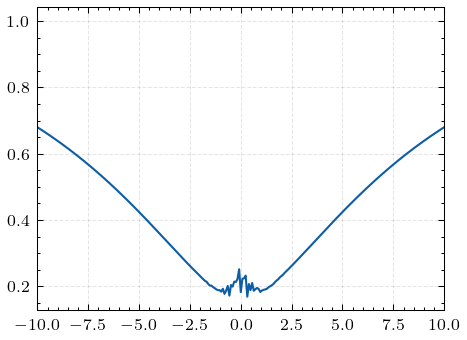

In [25]:
plt.plot(x_dark_st, norm(init_cond(x_dark_st)), "-", marker="none")
plt.xlim(-10, 10)

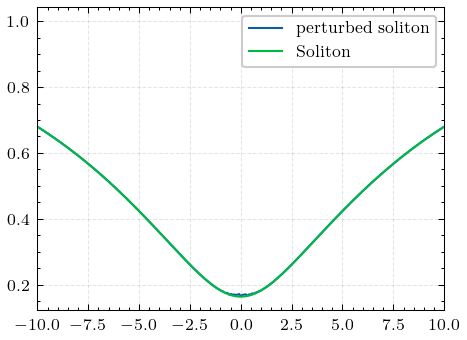

In [84]:
plt.plot(x_dark_st, norm(sol_gauss(x_dark_st, A_rand)), ls="-", marker="none", label="perturbed soliton")
plt.plot(x_dark_st, norm(w_dark_st(x_dark_st)), ls="-", marker="none", label="Soliton")
plt.xlim(-10, 10)
plt.legend()
plt.show()

In [26]:
w_st_gauss_rand = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_st_gauss_rand.set_init_condition(init_cond)
w_st_gauss_rand.solve(b_tol=1e-4)#method="fixed point")

Iteration  1  of  10000 . Newton Error:  7.566701607539673e-13 . Total iteration:  3
Iteration  2  of  10000 . Newton Error:  5.348429211085552e-13 . Total iteration:  3
Iteration  3  of  10000 . Newton Error:  9.674086311541555e-14 . Total iteration:  3
Iteration  4  of  10000 . Newton Error:  4.264612245138295e-14 . Total iteration:  3
Iteration  5  of  10000 . Newton Error:  3.63752829557735e-14 . Total iteration:  3
Iteration  6  of  10000 . Newton Error:  3.489031568520345e-14 . Total iteration:  3
Iteration  7  of  10000 . Newton Error:  5.517266071324897e-14 . Total iteration:  3
Iteration  8  of  10000 . Newton Error:  1.2432420064038622e-13 . Total iteration:  3
Iteration  9  of  10000 . Newton Error:  2.4606356099209538e-14 . Total iteration:  3
Iteration  10  of  10000 . Newton Error:  7.706705205331349e-14 . Total iteration:  3
Iteration  11  of  10000 . Newton Error:  2.0789108199968514e-13 . Total iteration:  3
Iteration  12  of  10000 . Newton Error:  4.0569868175510653e

KeyboardInterrupt: 

In [86]:
def theo_dark_st(x, t):
    output = w_dark_st(x - c_st*t)
    return output

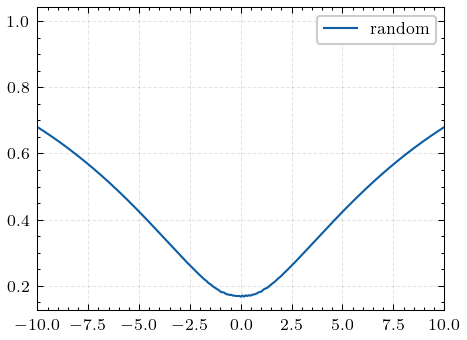

In [87]:
j = 50 #10000-1
plt.plot(w_st.x, norm(w_st_gauss_rand.w[j]), marker="none", ls="-", label="random") #norm(w_st.w[j])
#plt.plot(w_st.x, norm(theo_dark_st(w_st.x, w_st.t[j])), marker="none", ls="-", label="theo")
plt.legend()
plt.xlim(-10, 10)

plt.show()

In [88]:
#w_st.w_theo = theo_dark_st
#w_st_gauss_007.w_theo = theo_dark_st
w_st_gauss_rand.w_theo = theo_dark_st
#w_in_gauss_001.w_theo = theo_dark_in
#w_in_gauss_0001.w_theo = theo_dark_in
#w_in_gauss_00001.w_theo = theo_dark_in

#L2_errors_st = w_st.get_error()#np.zeros(len(w_in.w)-1)
#L2_errors_st_gauss_007 = w_st_gauss_007.get_error()#np.zeros(len(w_in.w)-1)
L2_errors_st_gauss_rand = w_st_gauss_rand.get_error()
#errors_gauss_001 = w_in_gauss_001.get_error()#np.zeros(len(w_in.w)-1)
#errors_gauss_0001 = w_in_gauss_0001.get_error()#np.zeros(len(w_in.w)-1)
#errors_gauss_00001 = w_in_gauss_00001.get_error()#np.zeros(len(w_in.w)-1)


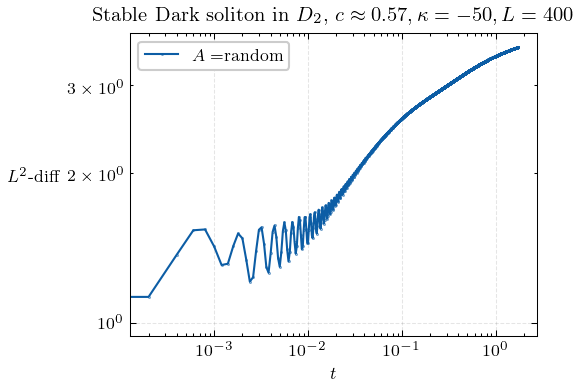

In [135]:
#slope = m_t_0(x_dark_st, A, k)
#m_0 = norm(A_rand * (np.pi/2)**(1/4))

ms = .5

cond = norm(w_st_gauss_rand.w) != 0

norm_g = np.sqrt(w_st_gauss_rand.h) * np.linalg.norm(g(x_dark_st, A_rand), ord=2)

#plt.plot(0, m_0**2, ms=2)
#plt.axline((0, m_0**2), slope=slope, linewidth=1)
#plt.plot(w_st.t, L2_errors_st**2, ".", label="Standard", ms=ms)
#plt.plot(w_st.t, L2_errors_st_gauss_007, ".", label=r"$A={}$".format(A), ms=ms) #**2
plt.plot(w_st_gauss_rand.t[cond[:, 0]], L2_errors_st_gauss_rand[cond[:, 0]]/norm_g, ".-", label=r"$A=$random", ms=ms)
#plt.plot(w_in.t, errors_gauss_001, ".", label=r"Gauss $A=10^{-2}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_0001, ".", label=r"Gauss $A=10^{-3}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_00001, ".", label=r"Gauss $A=10^{-4}$", ms=ms)
plt.xlabel(r"$t$")
plt.ylabel(r"$L^2$-diff", rotation='horizontal', ha='right')
plt.title(r"Stable Dark soliton in $D_2$, $c\approx{c}, \kappa={k}, L={L}$".format(c=round(c_st, 2), k=k, L=L))
plt.xscale("log")
plt.yscale("log")
plt.legend()
#plt.xlim(-0.01, 0.55)
#plt.ylim(0, 0.025)
#plt.ylim(-0.01, 0.02)
#plt.xlim(-0.1, 0.2)
#plt.xlim(-0.01, 0.4)
#plt.xlim(-0.001, 0.02)
#plt.ylim(-0.001, 0.01)
#plt.savefig("diffs/Dark_D2.png", dpi=300, bbox_inches = "tight")
plt.show()

(-3.0, 3.0)

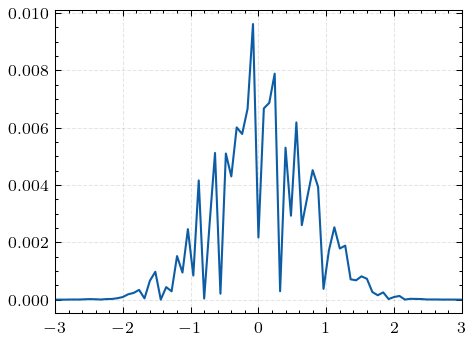

In [110]:
plt.plot(x_dark_st, g(x_dark_st, A_rand), marker="none", ls="-")
plt.xlim(-3, 3)